<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week7_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL P7 - SEGMENTASI CITRA DENGAN THRESHOLDING
## Tugas Individu
**Nama:** Rifo Anggi Barbara Danuarta  
**NIM:** 244107020063  
**Kelas:** 3F  
**No. Absen:** 24

In [1]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, segmentation

np.set_printoptions(suppress=True)
plt.rcParams['figure.figsize'] = (12, 6)

def tampilkan(images, titles, cols=3, figsize=None):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=figsize or (5 * cols, 4 * rows))
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if image.ndim == 3:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(image, cmap='gray')
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def baca_grayscale(path):
    image = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f'Citra tidak ditemukan atau tidak dapat dibaca: {path}')
    return image

print('OpenCV:', cv.__version__)

OpenCV: 5.0.0


## Persiapan Citra


In [2]:
# Jika memakai Google Drive, aktifkan dua baris berikut.
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/PCVK_2026'
# Untuk file yang diunggah langsung ke Colab, gunakan misalnya '/content/nama_file.jpg'.

def cari_citra(kandidat):
    for path in kandidat:
        if os.path.exists(path):
            return path
    return kandidat[0]

# Lena dicari berurutan: versi kontras rendah sesuai modul, lalu foto Lena apa pun yang tersedia.
PATH_LENA = cari_citra([
    os.path.join(BASE, 'lena_gs_lc2.jpg'),
    os.path.join(BASE, 'lena_lc.jpg'),
    os.path.join(BASE, 'lena.jpg'),
    '/content/lena_gs_lc2.jpg',
    '/content/lena_lc.jpg',
    '/content/lena.jpg',
])
PATH_SUDOKU = cari_citra([
    os.path.join(BASE, 'sudoku-original.jpg'),
    os.path.join(BASE, 'sudoku.jpg'),
    '/content/sudoku-original.jpg',
])
PATH_KTP = cari_citra([
    os.path.join(BASE, 'ktp_fulan.jpg'),
    os.path.join(BASE, 'ktp.jpg'),
    '/content/ktp_fulan.jpg',
])

print('Lena  :', PATH_LENA, '(ada)' if os.path.exists(PATH_LENA) else '(belum ada)')
print('Sudoku:', PATH_SUDOKU, '(ada)' if os.path.exists(PATH_SUDOKU) else '(belum ada)')
print('KTP   :', PATH_KTP, '(ada)' if os.path.exists(PATH_KTP) else '(belum ada)')
print('Catatan: jika path belum ada, unggah file lalu ubah variabel path.')

Mounted at /content/drive
Lena  : /content/drive/MyDrive/PCVK_2026/lena.jpg (ada)
Sudoku: /content/drive/MyDrive/PCVK_2026/sudoku-original.jpg (ada)
KTP   : /content/drive/MyDrive/PCVK_2026/ktp_fulan.jpg (ada)
Catatan: jika path belum ada, unggah file lalu ubah variabel path.


## 1. Global Threshold Manual

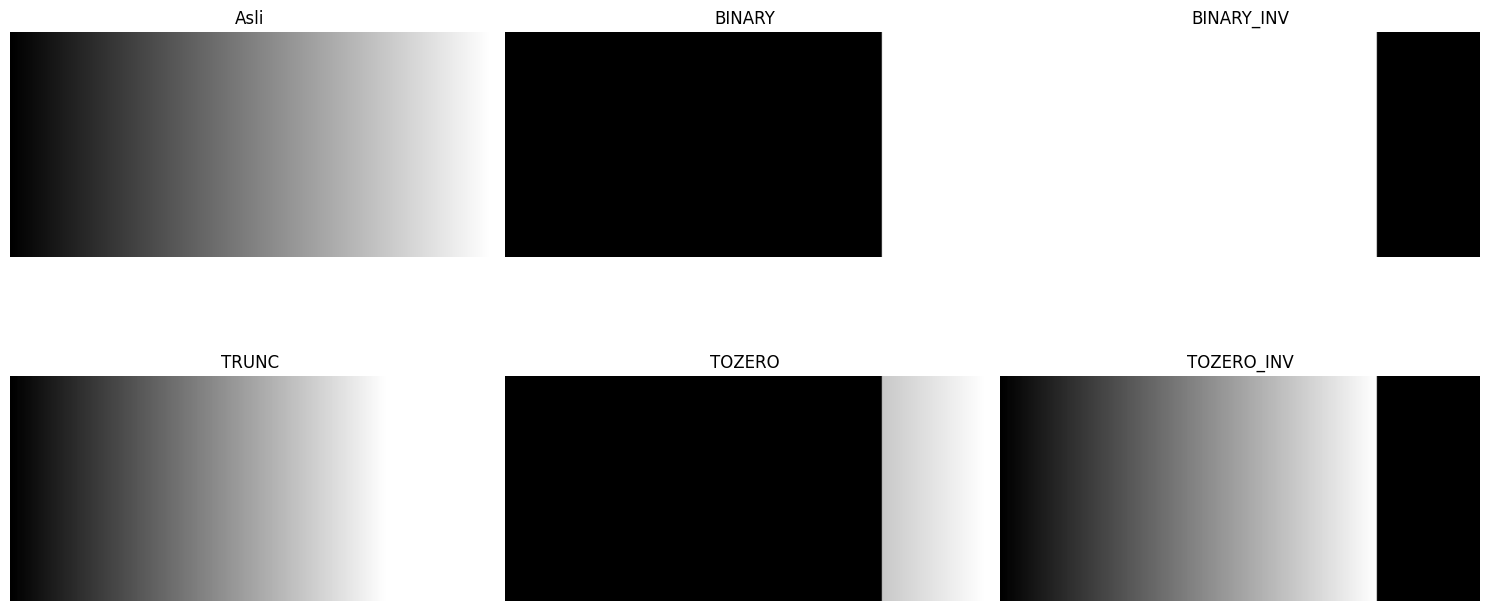

In [3]:
# Citra gradient dibuat agar efek kelima jenis threshold terlihat jelas.
gradient = np.tile(np.arange(256, dtype=np.uint8), (120, 1))
thresh = 200
maxval = 255

def global_threshold_manual(image, threshold=200, max_value=255, jenis='BINARY'):
    image = image.astype(np.uint8)
    result = image.copy()
    lebih = image > threshold
    if jenis == 'BINARY':
        result = np.where(lebih, max_value, 0)
    elif jenis == 'BINARY_INV':
        result = np.where(lebih, 0, max_value)
    elif jenis == 'TRUNC':
        result = np.where(lebih, threshold, image)
    elif jenis == 'TOZERO':
        result = np.where(lebih, image, 0)
    elif jenis == 'TOZERO_INV':
        result = np.where(lebih, 0, image)
    else:
        raise ValueError('Jenis threshold tidak dikenal.')
    return result.astype(np.uint8)

jenis_global = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil_global = [global_threshold_manual(gradient, thresh, maxval, jenis) for jenis in jenis_global]
tampilkan([gradient] + hasil_global, ['Asli'] + jenis_global, cols=3, figsize=(15, 8))

## 2. Adaptive Threshold Manual

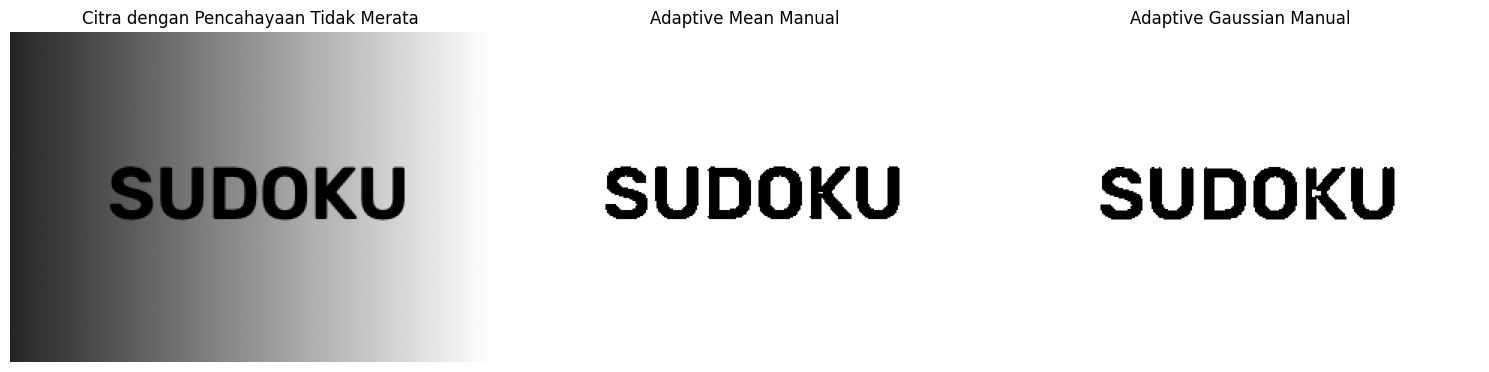

In [4]:
def gaussian_kernel_manual(size=11, sigma=2):
    radius = size // 2
    y, x = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    kernel = np.exp(-(x*x + y*y) / (2 * sigma*sigma))
    return kernel / kernel.sum()

def adaptive_mean_manual(gray, block_size=11, C=2):
    radius = block_size // 2
    padded = np.pad(gray.astype(np.float32), radius, mode='reflect')
    integral = np.pad(padded, ((1, 0), (1, 0)), mode='constant')
    integral = integral.cumsum(axis=0).cumsum(axis=1)
    local_sum = (integral[block_size:, block_size:] - integral[:-block_size, block_size:]
                 - integral[block_size:, :-block_size] + integral[:-block_size, :-block_size])
    local_mean = local_sum / (block_size * block_size)
    return np.where(gray > local_mean - C, 255, 0).astype(np.uint8)

def adaptive_gaussian_manual(gray, block_size=11, C=2, sigma=2):
    radius = block_size // 2
    padded = np.pad(gray.astype(np.float32), radius, mode='reflect')
    kernel = gaussian_kernel_manual(block_size, sigma)
    local_mean = np.zeros_like(gray, dtype=np.float32)
    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            window = padded[y:y + block_size, x:x + block_size]
            local_mean[y, x] = np.sum(window * kernel)
    return np.where(gray > local_mean - C, 255, 0).astype(np.uint8)

# Citra demo dengan pencahayaan tidak merata agar notebook tetap dapat dijalankan.
demo = np.tile(np.linspace(50, 220, 320, dtype=np.uint8), (220, 1))
cv.putText(demo, 'SUDOKU', (65, 125), cv.FONT_HERSHEY_SIMPLEX, 1.7, 20, 4)
adaptive_mean = adaptive_mean_manual(demo, 11, 2)
adaptive_gaussian = adaptive_gaussian_manual(demo, 11, 2, 2)
tampilkan([demo, adaptive_mean, adaptive_gaussian], ['Citra dengan Pencahayaan Tidak Merata', 'Adaptive Mean Manual', 'Adaptive Gaussian Manual'], cols=3)

### Adaptive Threshold pada Citra Sudoku

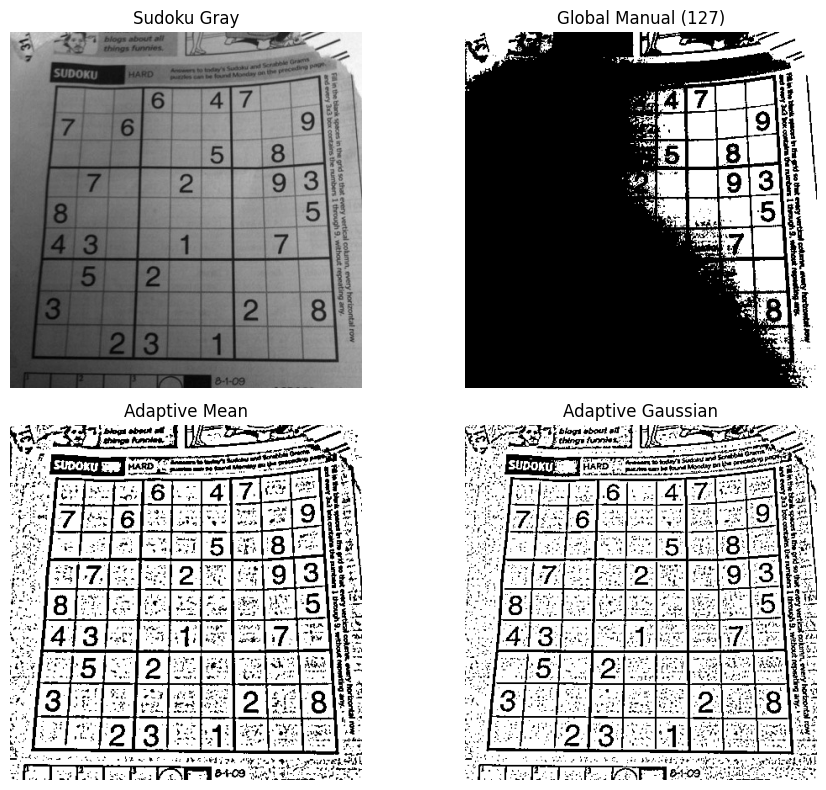

In [ ]:
if os.path.exists(PATH_SUDOKU):
    sudoku = baca_grayscale(PATH_SUDOKU)
    sudoku_mean = adaptive_mean_manual(sudoku, 11, 2)
    sudoku_gaussian = adaptive_gaussian_manual(sudoku, 11, 2, 2)
    sudoku_global = global_threshold_manual(sudoku, 127, 255, 'BINARY')
    tampilkan([sudoku, sudoku_global, sudoku_mean, sudoku_gaussian], ['Sudoku Gray', 'Global Manual (127)', 'Adaptive Mean', 'Adaptive Gaussian'], cols=2)
else:
    print('PATH_SUDOKU belum tersedia. Unggah sudoku-original.jpg dan jalankan kembali sel ini.')

## 3. Otsu Threshold Manual

Citra Lena: shape=(512, 512), dtype=uint8, 2D grayscale=True
Rentang intensitas Lena grayscale: 0 sampai 255
Rentang kontras rendah: 85 sampai 108 (semua < 127)
Threshold Otsu pada citra kontras rendah: 94


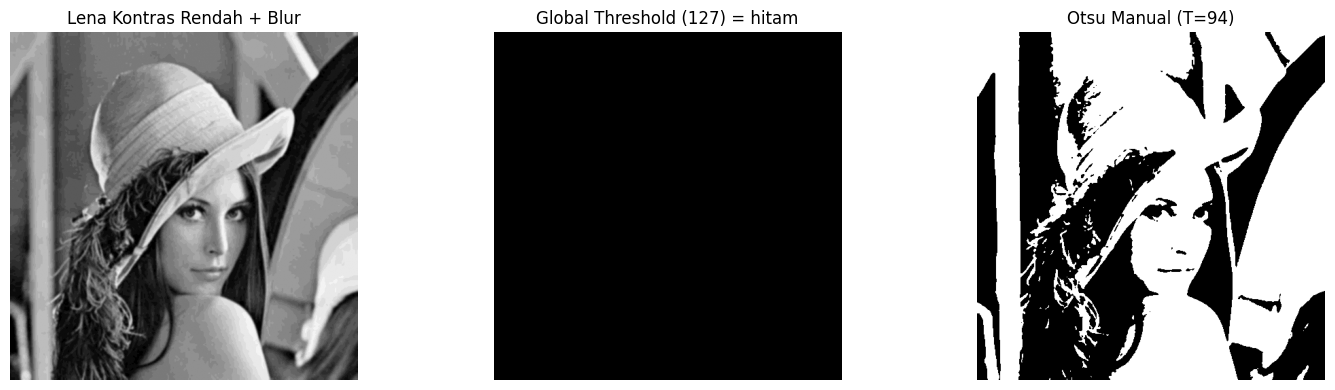

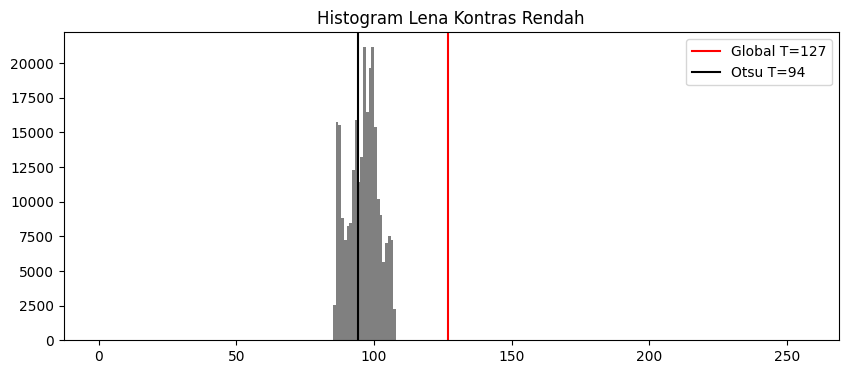

Threshold Otsu Lena asli: 113
Jawaban: agar objek Lena tetap terlihat, gunakan ambang sekitar 94 (Otsu) yang berada di dalam rentang intensitas, bukan 127.


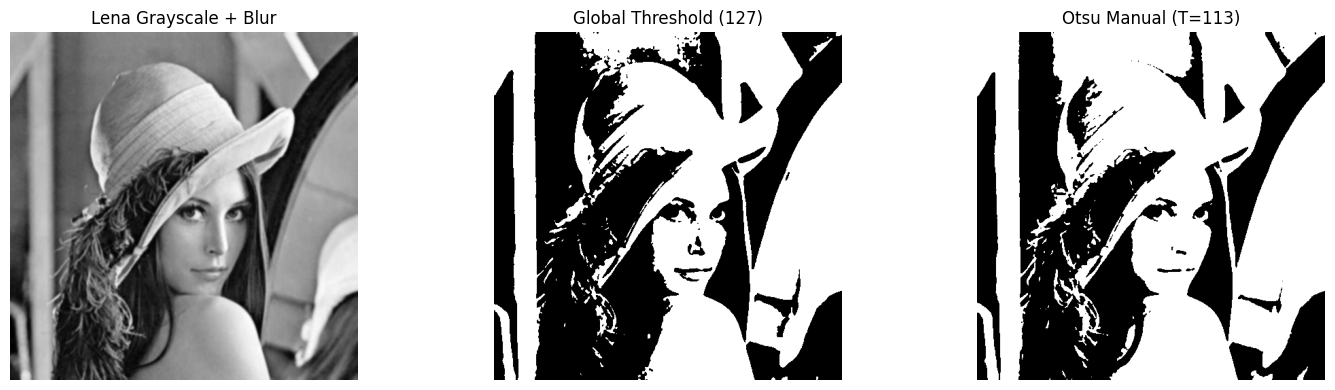

In [5]:
def otsu_manual(gray):
    gray = gray.astype(np.uint8)
    histogram = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    total = gray.size
    nilai = np.arange(256, dtype=np.float64)
    total_sum = np.sum(nilai * histogram)
    weight_background = 0.0
    sum_background = 0.0
    best_threshold = 0
    best_variance = -1.0
    for t in range(256):
        weight_background += histogram[t] / total
        sum_background += t * histogram[t] / total
        weight_foreground = 1.0 - weight_background
        if weight_background == 0 or weight_foreground == 0:
            continue
        mean_background = sum_background / weight_background
        mean_total = total_sum / total
        mean_foreground = (mean_total - sum_background) / weight_foreground
        variance_between = (weight_background * weight_foreground *
                           (mean_background - mean_foreground) ** 2)
        if variance_between > best_variance:
            best_variance = variance_between
            best_threshold = t
    binary = np.where(gray > best_threshold, 255, 0).astype(np.uint8)
    return binary, best_threshold

def jadikan_kontras_rendah(gray, low=85, high=108):
    gray_f = gray.astype(np.float32)
    lo, hi = float(gray_f.min()), float(gray_f.max())
    if hi <= lo:
        return np.full_like(gray, low, dtype=np.uint8)
    skala = (gray_f - lo) / (hi - lo)
    return (low + skala * (high - low)).astype(np.uint8)

if os.path.exists(PATH_LENA):
    lena = baca_grayscale(PATH_LENA)   # citra warna apa pun langsung dikonversi ke grayscale
    print(f'Citra Lena: shape={lena.shape}, dtype={lena.dtype}, 2D grayscale={lena.ndim == 2}')
    print(f'Rentang intensitas Lena grayscale: {lena.min()} sampai {lena.max()}')

    # Versi kontras rendah meniru lena_gs_lc2.jpg (seluruh intensitas di bawah 127).
    lena_lc = jadikan_kontras_rendah(lena, 85, 108)
    lena_lc_blur = cv.GaussianBlur(lena_lc, (5, 5), 0)
    lc_global = global_threshold_manual(lena_lc_blur, 127, 255, 'BINARY')
    lc_otsu, lc_t = otsu_manual(lena_lc_blur)
    print(f'Rentang kontras rendah: {lena_lc_blur.min()} sampai {lena_lc_blur.max()} (semua < 127)')
    print(f'Threshold Otsu pada citra kontras rendah: {lc_t}')
    tampilkan([lena_lc_blur, lc_global, lc_otsu], ['Lena Kontras Rendah + Blur', 'Global Threshold (127) = hitam', f'Otsu Manual (T={lc_t})'], cols=3)
    plt.figure(figsize=(10, 4))
    plt.hist(lena_lc_blur.ravel(), bins=256, range=(0, 256), color='gray')
    plt.axvline(127, color='red', label='Global T=127')
    plt.axvline(lc_t, color='black', label=f'Otsu T={lc_t}')
    plt.title('Histogram Lena Kontras Rendah')
    plt.legend()
    plt.show()

    # Pembanding: Otsu pada citra Lena grayscale apa adanya.
    lena_blur = cv.GaussianBlur(lena, (5, 5), 0)
    lena_otsu, lena_t = otsu_manual(lena_blur)
    lena_global = global_threshold_manual(lena_blur, 127, 255, 'BINARY')
    print(f'Threshold Otsu Lena asli: {lena_t}')
    print(f'Jawaban: agar objek Lena tetap terlihat, gunakan ambang sekitar {lc_t} (Otsu) yang berada di dalam rentang intensitas, bukan 127.')
    tampilkan([lena_blur, lena_global, lena_otsu], ['Lena Grayscale + Blur', 'Global Threshold (127)', f'Otsu Manual (T={lena_t})'], cols=3)
else:
    print('PATH_LENA belum tersedia. Unggah lena.jpg (atau lena_gs_lc2.jpg) lalu jalankan ulang sel ini.')

Threshold Otsu OpenCV: 113.0


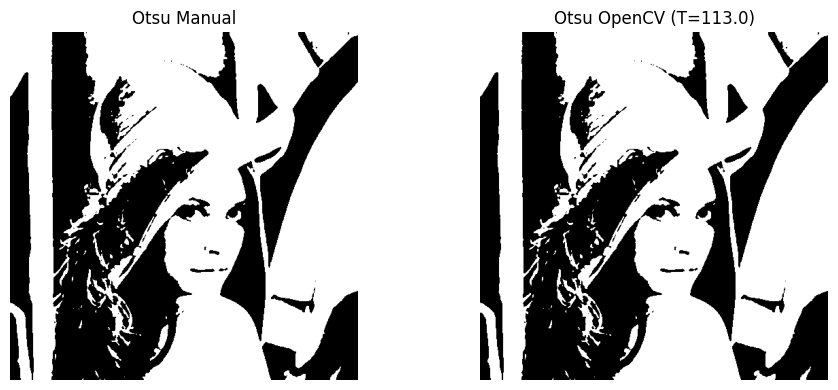

In [7]:
# Pembanding dengan library OpenCV, sesuai modul.
if os.path.exists(PATH_LENA):
    library_t, library_binary = cv.threshold(lena_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    print(f'Threshold Otsu OpenCV: {library_t}')
    tampilkan([lena_otsu, library_binary], ['Otsu Manual', f'Otsu OpenCV (T={library_t})'], cols=2)
else:
    print('Jalankan sel Otsu manual setelah citra Lena tersedia.')

**Analisis Lena (Tugas 3):** Pada citra Lena kontras rendah (mis. rentang 85-108 seperti `lena_gs_lc2.jpg`), seluruh piksel bernilai di bawah 127. Karena Binary Threshold hanya mengubah piksel bernilai `> 127` menjadi putih, tidak ada satu pun piksel yang memenuhi syarat, sehingga seluruh citra menjadi 0 (hitam semua). Pada histogram, seluruh batang berada di sebelah kiri garis merah T=127. Agar objek Lena tetap terlihat, ambang harus berada di dalam rentang intensitas citra, yaitu sekitar nilai Otsu (di bawah 108), bukan 127. Nilai Otsu yang dipakai tercetak pada output sel di atas. Karena `lena.jpg` asli memiliki kontras penuh (0-255), citra kontras rendah dibuat otomatis pada sel di atas agar kasus ini dapat dibuktikan.

### Otsu pada Citra KTP (Tugas 5B)


Threshold Otsu KTP: 150
Rentang intensitas KTP: 0 sampai 255


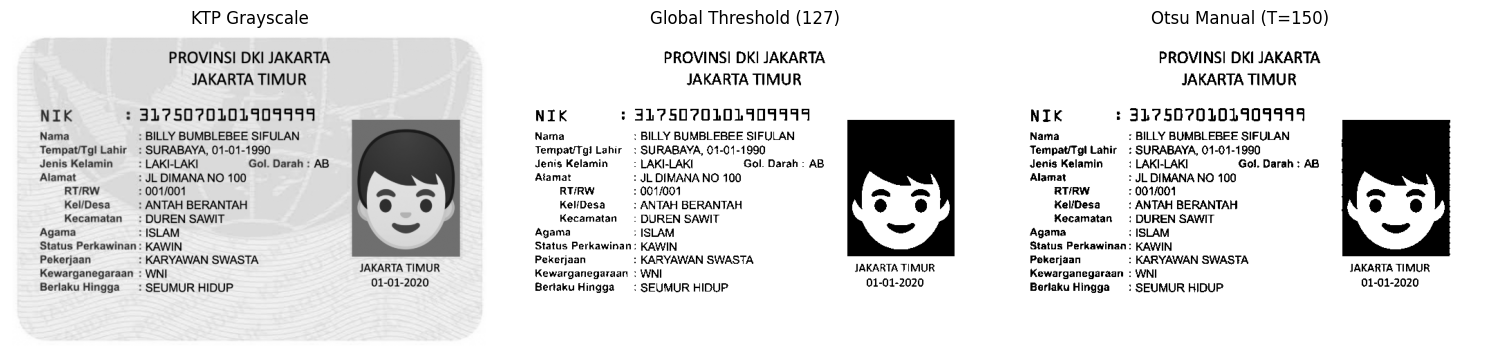

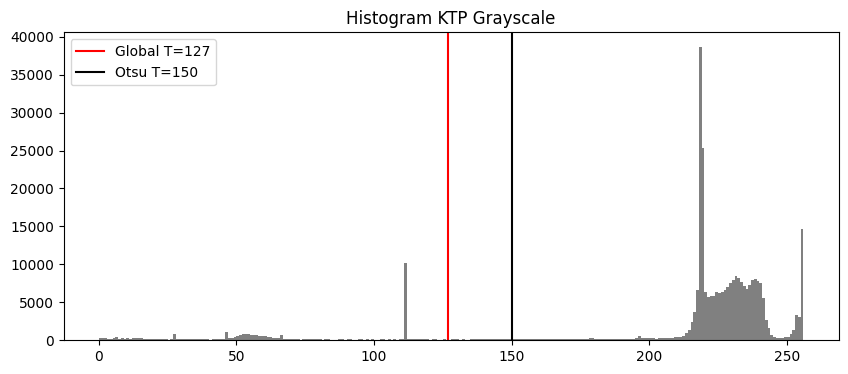

In [8]:
if os.path.exists(PATH_KTP):
    ktp_gray = baca_grayscale(PATH_KTP)
    ktp_otsu, ktp_t = otsu_manual(ktp_gray)
    ktp_global = global_threshold_manual(ktp_gray, 127, 255, 'BINARY')
    print(f'Threshold Otsu KTP: {ktp_t}')
    print(f'Rentang intensitas KTP: {ktp_gray.min()} sampai {ktp_gray.max()}')
    tampilkan([ktp_gray, ktp_global, ktp_otsu], ['KTP Grayscale', 'Global Threshold (127)', f'Otsu Manual (T={ktp_t})'], cols=3)
    plt.figure(figsize=(10, 4))
    plt.hist(ktp_gray.ravel(), bins=256, range=(0, 256), color='gray')
    plt.axvline(127, color='red', label='Global T=127')
    plt.axvline(ktp_t, color='black', label=f'Otsu T={ktp_t}')
    plt.title('Histogram KTP Grayscale')
    plt.legend()
    plt.show()
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg untuk mengerjakan Tugas 5B.')

**Analisis KTP (Tugas 5B):** Berbeda dengan citra Lena kontras rendah, citra KTP umumnya memiliki kontras dan pencahayaan yang tidak merata. Global threshold dengan ambang tetap 127 sering gagal memisahkan teks dari latar (sebagian area menjadi hitam total atau putih total). Otsu menghitung ambang otomatis dari histogram sehingga pemisahan objek dan latar lebih baik. Bandingkan nilai `ktp_t` (Otsu) dengan 127 pada output di atas untuk melihat perbedaannya.

## 4. Segmentasi Berbasis Region pada `data.coins()`


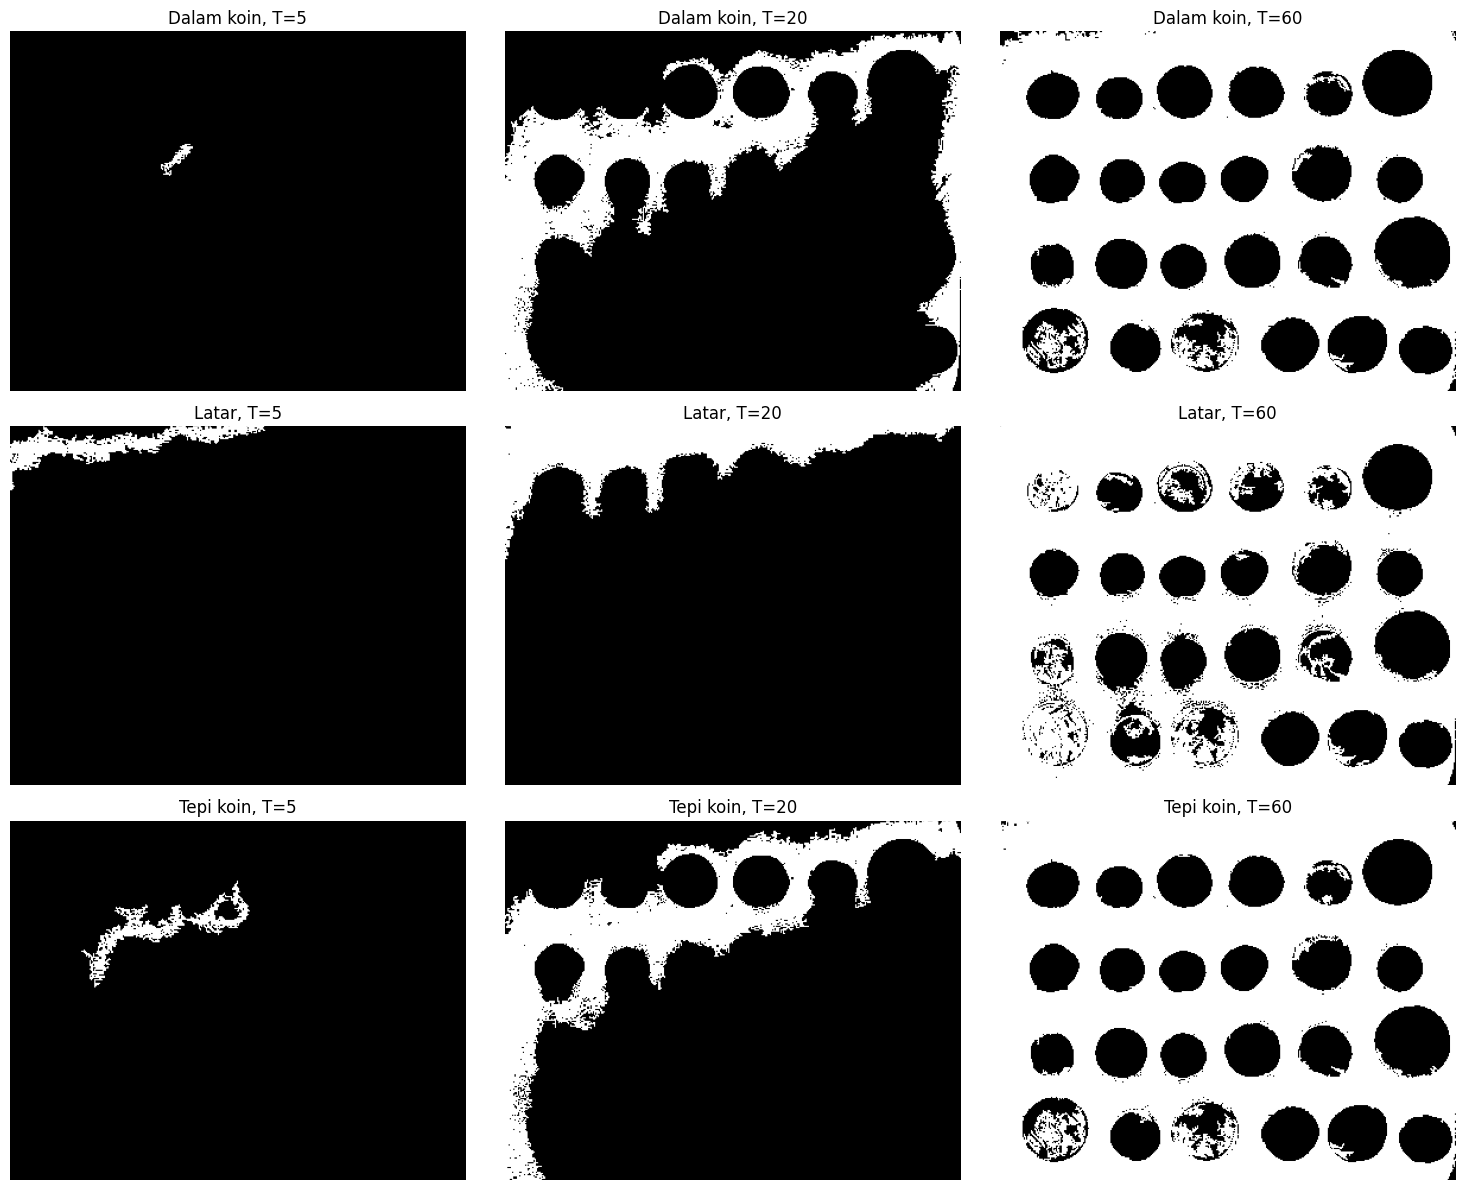

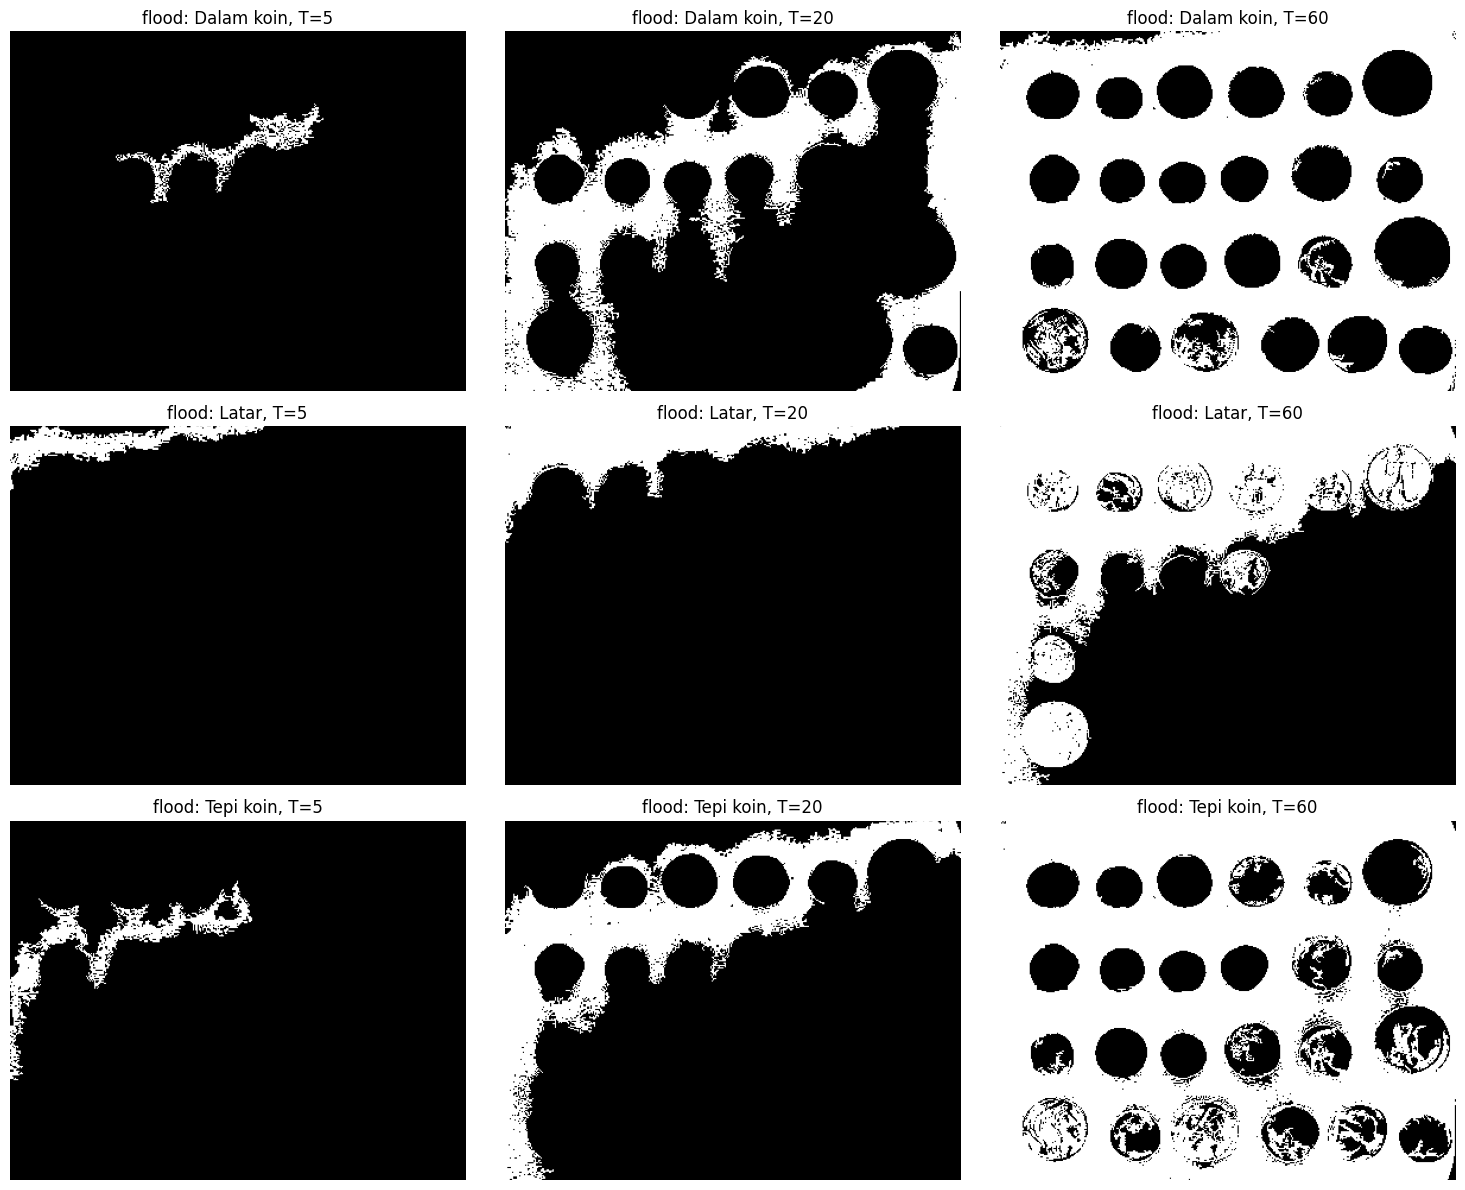

In [9]:
coins = data.coins()

def region_growing(gray, seed, tolerance):
    h, w = gray.shape
    sy, sx = seed
    seed_value = float(gray[sy, sx])
    region_sum = seed_value
    region_count = 1
    mask = np.zeros((h, w), dtype=bool)
    visited = np.zeros((h, w), dtype=bool)
    mask[sy, sx] = True
    visited[sy, sx] = True
    queue = [(sy, sx)]
    while queue:
        y, x = queue.pop(0)
        region_mean = region_sum / region_count
        diterima = mask[y, x] or abs(float(gray[y, x]) - region_mean) < tolerance
        if diterima:
            if not mask[y, x]:
                mask[y, x] = True
                region_sum += float(gray[y, x])
                region_count += 1
            for dy, dx in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                ny, nx = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx < w and not visited[ny, nx]:
                    visited[ny, nx] = True
                    queue.append((ny, nx))
    return mask

# Seed contoh: koin, latar, dan tepi. Sesuaikan koordinat bila diperlukan.
seeds = {'Dalam koin': (100, 150), 'Latar': (20, 20), 'Tepi koin': (95, 120)}
tolerances = [5, 20, 60]
plt.figure(figsize=(15, 12))
for row, (seed_name, seed) in enumerate(seeds.items()):
    for col, tolerance in enumerate(tolerances):
        mask = region_growing(coins, seed, tolerance)
        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(mask, cmap='gray')
        plt.title(f'{seed_name}, T={tolerance}')
        plt.axis('off')
plt.tight_layout()
plt.show()

# flood() memakai toleransi terhadap intensitas seed dan keterhubungan piksel.
plt.figure(figsize=(15, 12))
for row, (seed_name, seed) in enumerate(seeds.items()):
    for col, tolerance in enumerate(tolerances):
        mask = segmentation.flood(coins, seed, tolerance=tolerance)
        plt.subplot(3, 3, row * 3 + col + 1)
        plt.imshow(mask, cmap='gray')
        plt.title(f'flood: {seed_name}, T={tolerance}')
        plt.axis('off')
plt.tight_layout()
plt.show()

## 5. Segmentasi Warna Biru pada KTP


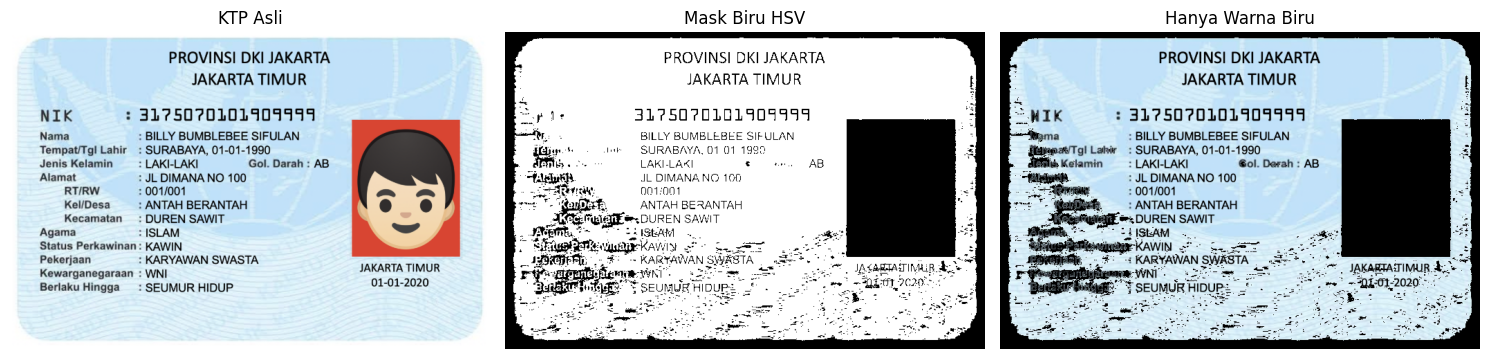

In [10]:
if os.path.exists(PATH_KTP):
    ktp = cv.imread(PATH_KTP)
    hsv = cv.cvtColor(ktp, cv.COLOR_BGR2HSV)
    H, S, V = cv.split(hsv)
    kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
    mask_biru = (kelompok_biru.astype(np.uint8) * 255)
    hanya_biru = cv.bitwise_and(ktp, ktp, mask=mask_biru)
    tampilkan([ktp, mask_biru, hanya_biru], ['KTP Asli', 'Mask Biru HSV', 'Hanya Warna Biru'], cols=3)
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg milik sendiri dan jalankan ulang sel ini.')

### Pelengkap: K-Means pada Warna KTP
K-Means mengelompokkan piksel berdasarkan kedekatan warna. Cluster yang paling dekat dengan warna biru dipertahankan sebagai segmentasi warna biru.

Pusat cluster RGB:
[[212 233 245]
 [ 43  45  46]
 [215  69  50]
 [149 153 155]]
Cluster biru terpilih: 0


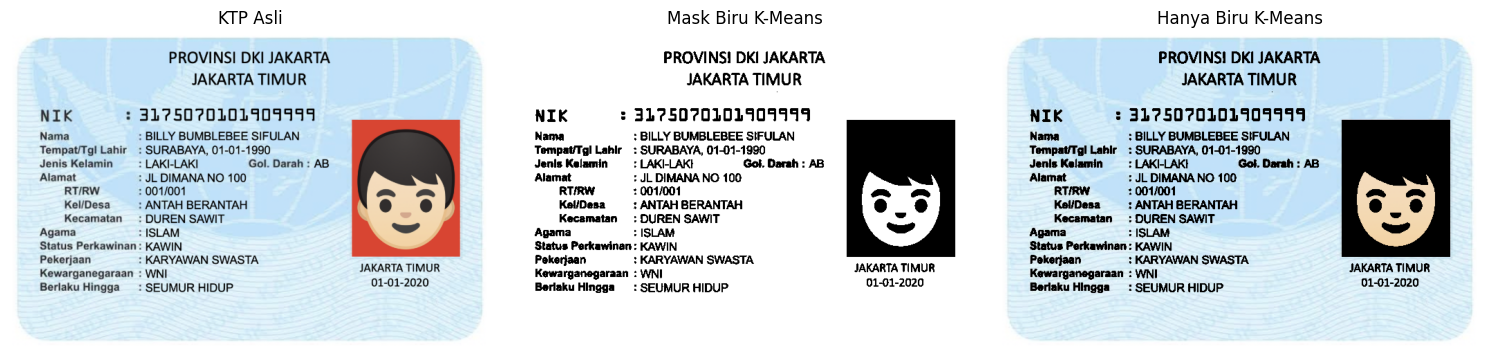

In [11]:
if os.path.exists(PATH_KTP):
    from sklearn.cluster import KMeans

    ktp_rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)
    piksel = np.float32(ktp_rgb.reshape((-1, 3)))
    k = 4
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(piksel)
    centers = kmeans.cluster_centers_

    # Warna biru memiliki komponen B relatif tinggi dibanding R dan G.
    blue_score = centers[:, 2] - (centers[:, 0] + centers[:, 1]) / 2
    blue_cluster = int(np.argmax(blue_score))
    mask_kmeans = (labels == blue_cluster).astype(np.uint8).reshape(ktp.shape[:2]) * 255
    ktp_blue_kmeans = cv.bitwise_and(ktp, ktp, mask=mask_kmeans)

    print('Pusat cluster RGB:')
    print(np.uint8(centers))
    print(f'Cluster biru terpilih: {blue_cluster}')
    tampilkan([ktp, mask_kmeans, ktp_blue_kmeans], ['KTP Asli', 'Mask Biru K-Means', 'Hanya Biru K-Means'], cols=3)
else:
    print('PATH_KTP belum tersedia. Unggah ktp_fulan.jpg untuk menjalankan K-Means.')

## Kesimpulan
Global threshold cocok saat pencahayaan merata dan histogram terpisah. Adaptive threshold lebih sesuai untuk pencahayaan tidak merata karena ambangnya dihitung dari lingkungan lokal. Otsu memilih ambang otomatis berdasarkan histogram. Region growing mempertimbangkan keterhubungan piksel, sedangkan masking HSV dapat mengekstrak kelompok warna tertentu seperti biru pada KTP.